# Cross-Checking DINOv2 Similarity Search on MiraBest: A Second, Independent Dataset

**Phase 2, Step 1** of the *radio-source-discovery* project
(https://github.com/tallhaishtiaque/radio-source-discovery)

**Author:** Talha Ishtiaque

---

## Purpose

The Phase 1 baseline notebook established that frozen, general-purpose DINOv2
embeddings retrieve bent-tailed radio galaxies from the Aniyan & Thorat (2017)
dataset at roughly twice the rate of random chance (precision@20 = 0.523 vs.
0.248 baseline). A single dataset is not sufficient evidence that this result
reflects something general about the method, rather than something specific
to that one dataset's imaging, preprocessing, or class balance.

This notebook repeats the **identical** evaluation protocol — same model
(`dinov2_vits14`), same preprocessing, same leave-one-out needle-in-a-haystack
metric, imported directly from the project's own `src/eval/needle_in_haystack.py`
— on MiraBest (Porter & Scaife 2023), a second, independent, and more widely
used benchmark. If the method's roughly 2x-over-random result holds on this
second dataset too, that is real evidence of generality rather than a
dataset-specific artefact.

## Rare-class choice: wide-angle-tail

MiraBest's fine-grained sub-morphology labels include *wide-angle-tail* (WAT)
sources — a bent-jet morphology directly analogous to the "bent-tailed" class
used in Phase 1, arising from the same underlying physics (motion through the
intracluster medium). We use WAT as this notebook's rare class, keeping the
scientific target consistent across both datasets even though the source
datasets themselves are independent.

## What you will see in this notebook

| Figure | Question it answers |
|---|---|
| **Fig 0** | What is in the "haystack"? How rare is the rare class? |
| **Fig 1** | Headline: does the method beat random guessing on this second dataset, and how does it compare with Phase 1 (using a prevalence-fair score)? |
| **Fig 2** | How does performance change as the result list gets longer (k = 1 → 50)? |
| **Fig 3** | Is the method consistent query-by-query, or does it just get lucky on average? |
| **Fig 4** | Can you literally *see* the rare class as a cluster in embedding space? |
| **Fig 5** | What does a successful search, a typical one and a failed one actually look like? |
| **Fig 6** | When it is wrong, *what* does it confuse wide-angle-tails with? |

Colour code used throughout: **blue = Phase 1** (Aniyan & Thorat, bent-tailed),
**orange = Phase 2** (MiraBest, wide-angle-tail), **grey = random guessing**.


## 1. Setup

**To run this on Kaggle:** create a new notebook, enable a GPU accelerator and
Internet access (Settings panel), then run all cells. Unlike Phase 1, no
Kaggle dataset needs to be attached — this notebook downloads MiraBest
directly from Zenodo at runtime.


In [1]:
!pip install faiss-cpu -q


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.8/18.8 MB 73.8 MB/s eta 0:00:00


In [2]:
import io
import pickle
import random
import tarfile
import zipfile
from pathlib import Path

import numpy as np
import requests
import torch
import faiss
import matplotlib.pyplot as plt
from PIL import Image
from torchvision import transforms
from tqdm.auto import tqdm
from sklearn.decomposition import PCA

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using device: {DEVICE}")
if DEVICE == "cpu":
    print("Warning: no GPU detected — enable a GPU accelerator in Kaggle's Settings panel.")


Using device: cuda


## 2. Locate and download the correct MiraBest loader from Zenodo

**Important correction from the first version of this notebook:** MiraBest
exists in **two separate Zenodo records**. Record `4288837` (used
previously) turned out to only carry **binary FRI/FRII labels** (`labels`
key, values `[0, 1]`) — no sub-morphology information at all, confirmed by
actually running that version and inspecting its real output. Record
`5588282`, "MiraBest Batched Dataset" (Version 2.0), is described directly
on its own Zenodo page as using the fuller three-digit scheme (FRI/FRII/
hybrid × confident/uncertain × standard/double-double/**wide-angle-tail**/
head-tail) — this is the one we actually need, and this notebook now uses it.

Rather than hand-parsing raw pickle files ourselves again (which is what
caused the previous round of bugs), this notebook downloads the record's
**official loader class** and uses it directly — letting the dataset's own
code handle its own format correctly, rather than us re-guessing it.


In [3]:
ZENODO_RECORD_ID = "5588282"  # MiraBest Batched Dataset, v2.0 -- has the full label scheme

resp = requests.get(f"https://zenodo.org/api/records/{ZENODO_RECORD_ID}", timeout=30)
resp.raise_for_status()
record = resp.json()

print("Record title:", record.get("metadata", {}).get("title"))
print("\nFiles in this record:")
files = record.get("files", [])
for f in files:
    size_kb = f.get("size", 0) / 1024
    print(f"  {f['key']:40s}  {size_kb:8.2f} KB")

if not files:
    raise RuntimeError(
        "No files listed for this Zenodo record. Search 'MiraBest Batched "
        "Dataset Zenodo' to find the current record page and update "
        "ZENODO_RECORD_ID above."
    )


Record title: MiraBest Batched Dataset

Files in this record:
  MiraBest_N.py                                16.60 KB
  README.md                                     1.75 KB
  MiraBest_F.py                                16.55 KB


In [4]:
DOWNLOAD_DIR = Path("mirabest_loader")
DOWNLOAD_DIR.mkdir(exist_ok=True)

downloaded_paths = {}
for f in files:
    out_path = DOWNLOAD_DIR / f["key"]
    if not out_path.exists():
        print(f"Downloading {f['key']} ...")
        r = requests.get(f["links"]["self"], timeout=120)
        r.raise_for_status()
        out_path.write_bytes(r.content)
    downloaded_paths[f["key"]] = out_path
    print(f"  {out_path}  ({out_path.stat().st_size / 1024:.1f} KB)")


  mirabest_loader/MiraBest_N.py  (16.6 KB)
  mirabest_loader/README.md  (1.7 KB)
  mirabest_loader/MiraBest_F.py  (16.5 KB)


## 3. Import the loader and find its Dataset class(es) by introspection

Rather than assuming a class name we haven't verified, we import the
downloaded module and search it for classes that behave like a PyTorch
`Dataset` (i.e. define `__getitem__` and `__len__`) — the dataset's own
paper mentions child classes for confident/uncertain/hybrid subsamples, so
more than one such class may be defined here. We print all of them, along
with their `__init__` signatures, so nothing about how to instantiate them
is guessed blind.


In [5]:
import importlib.util
import inspect

MIRABEST_MODULE_PATH = downloaded_paths.get("MiraBest_F.py")
if MIRABEST_MODULE_PATH is None:
    # Fall back to whatever .py file was actually downloaded, in case the
    # filename differs from what we expected.
    py_files = [p for p in downloaded_paths.values() if p.suffix == ".py"]
    if not py_files:
        raise RuntimeError("No .py loader file found in the downloaded record files.")
    MIRABEST_MODULE_PATH = py_files[0]

print(f"Loading module from: {MIRABEST_MODULE_PATH}")
spec = importlib.util.spec_from_file_location("mirabest_loader", MIRABEST_MODULE_PATH)
mirabest_module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(mirabest_module)

dataset_classes = []
for name, obj in inspect.getmembers(mirabest_module, inspect.isclass):
    if hasattr(obj, "__getitem__") and hasattr(obj, "__len__") and obj.__module__ == mirabest_module.__name__:
        dataset_classes.append((name, obj))

print(f"\nFound {len(dataset_classes)} candidate Dataset-like class(es):")
for name, obj in dataset_classes:
    try:
        sig = inspect.signature(obj.__init__)
    except (TypeError, ValueError):
        sig = "(signature unavailable)"
    print(f"  {name}{sig}")

if not dataset_classes:
    raise RuntimeError(
        "No Dataset-like classes found in the loaded module. Inspect "
        f"{MIRABEST_MODULE_PATH} directly (view it as a file) to find the "
        "correct class name and constructor manually."
    )


Loading module from: mirabest_loader/MiraBest_F.py

Found 6 candidate Dataset-like class(es):
  MBFRConfident(self, *args, **kwargs)
  MBFRFull(self, *args, **kwargs)
  MBFRUncertain(self, *args, **kwargs)
  MBHybrid(self, *args, **kwargs)
  MBRandom(self, certainty='all', morphologies='all', *args, **kwargs)
  MiraBest_F(self, root, train=True, transform=None, target_transform=None, download=False)


## 4. Instantiate each candidate class and inspect its real labels

We try each candidate class with the standard MNIST/CIFAR-style constructor
convention this dataset's paper says it mimics (`root=..., train=True,
download=True`), then pull every sample via `dataset[i]` — the one part of
a PyTorch `Dataset`'s interface that is *guaranteed* to work regardless of
what its internal attributes happen to be named. We print how many distinct
label values each class exposes: a class with only 2 unique values is
almost certainly binary FRI/FRII (not useful here), while one with more
values is our real fine-grained target.


In [6]:
DATA_ROOT = Path("mirabest_data")
DATA_ROOT.mkdir(exist_ok=True)

def try_instantiate_and_summarize(cls, root, train):
    try:
        ds = cls(root=str(root), train=train, download=True)
    except TypeError as e:
        print(f"  Could not instantiate {cls.__name__}(root=..., train={train}, download=True): {e}")
        print(f"  Real signature: {inspect.signature(cls.__init__)}")
        return None
    labels = []
    n = len(ds)
    sample_size = min(n, 2000)  # cap for speed during this diagnostic pass
    for i in range(sample_size):
        item = ds[i]
        # Standard convention is (image, label), but handle other shapes defensively.
        label = item[1] if isinstance(item, (tuple, list)) and len(item) >= 2 else None
        labels.append(label)
    unique_vals = sorted(set(labels), key=lambda x: (x is None, x))
    print(f"  {cls.__name__}(train={train}): {n} total samples, "
          f"{len(unique_vals)} unique label value(s) in first {sample_size}: {unique_vals}")
    return ds, unique_vals

results_by_class = {}
for name, cls in dataset_classes:
    print(f"\n--- {name} ---")
    for train_flag in (True, False):
        r = try_instantiate_and_summarize(cls, DATA_ROOT, train_flag)
        if r is not None:
            results_by_class[(name, train_flag)] = r



--- MBFRConfident ---


100%|██████████| 766k/766k [00:00<00:00, 1.87MB/s]


  MBFRConfident(train=True): 729 total samples, 2 unique label value(s) in first 729: [0, 1]
  MBFRConfident(train=False): 104 total samples, 2 unique label value(s) in first 104: [0, 1]

--- MBFRFull ---
  MBFRFull(train=True): 1069 total samples, 2 unique label value(s) in first 1069: [0, 1]
  MBFRFull(train=False): 153 total samples, 2 unique label value(s) in first 153: [0, 1]

--- MBFRUncertain ---
  MBFRUncertain(train=True): 340 total samples, 2 unique label value(s) in first 340: [0, 1]
  MBFRUncertain(train=False): 49 total samples, 2 unique label value(s) in first 49: [0, 1]

--- MBHybrid ---
  MBHybrid(train=True): 30 total samples, 2 unique label value(s) in first 30: [0, 1]
  MBHybrid(train=False): 4 total samples, 2 unique label value(s) in first 4: [0, 1]

--- MBRandom ---
  MBRandom(train=True): 13 total samples, 1 unique label value(s) in first 13: [9]
  MBRandom(train=False): 94 total samples, 5 unique label value(s) in first 94: [0, 5, 6, 7, 8]

--- MiraBest_F ---
  

**Check the printed unique-label counts above.** The class/split
combination with **more than 2** unique values is the one carrying the
fine-grained three-digit scheme we need — set `CHOSEN_CLASS_NAME` below to
match it. If every class shows only 2 unique values, paste the full output
above back for help — it may mean this record's classes only expose the
coarse view too, and we'd need a different approach (e.g. cross-matching
`MiraBest.py`'s filenames against the original Miraghaei & Best catalogue).


In [7]:
# Set this based on what Section 4 actually printed — pick whichever class
# showed more than 2 unique label values.
CHOSEN_CLASS_NAME = None  # e.g. "MBFRFull" -- set once Section 4's output is checked

if CHOSEN_CLASS_NAME is None:
    # Best-effort auto-pick: choose whichever result has the most unique values.
    best_key = max(results_by_class, key=lambda k: len(results_by_class[k][1]))
    print(f"CHOSEN_CLASS_NAME not set manually — auto-picking based on most unique "
          f"label values found: {best_key[0]} (train={best_key[1]}), "
          f"{len(results_by_class[best_key][1])} unique values.")
else:
    matches = [k for k in results_by_class if k[0] == CHOSEN_CLASS_NAME]
    if not matches:
        raise RuntimeError(f"No results found for CHOSEN_CLASS_NAME={CHOSEN_CLASS_NAME!r}. "
                            f"Available: {list(results_by_class.keys())}")
    best_key = matches[0]

train_ds, train_unique = results_by_class[(best_key[0], True)]
test_ds, test_unique = results_by_class.get((best_key[0], False), (None, []))
print(f"\nUsing class: {best_key[0]}")
print(f"Train unique labels: {train_unique}")
if test_ds is not None:
    print(f"Test unique labels: {test_unique}")


CHOSEN_CLASS_NAME not set manually — auto-picking based on most unique label values found: MiraBest_F (train=True), 10 unique values.

Using class: MiraBest_F
Train unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]
Test unique labels: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 5. Extract all images and labels via the dataset's own `__getitem__`

This loads every sample through the class's own indexing protocol — the
same code path the dataset's authors use themselves — rather than parsing
pickle internals by hand.


In [8]:
def to_uint8_2d(img):
    # Convert whatever the loader returns (PIL image, array or tensor; 2-D or
    # with a channel axis; uint8 or float) into a plain 2-D uint8 image.
    a = np.squeeze(np.array(img))
    if a.ndim == 3:                       # collapse a channel axis to grayscale
        a = a.mean(axis=int(np.argmin(a.shape)))
    if a.dtype != np.uint8:
        a = a.astype(np.float32)
        if a.max() <= 1.0 + 1e-6:         # float images scaled to [0, 1]
            a = a * 255.0
        a = np.clip(a, 0, 255).astype(np.uint8)
    return a

def extract_all(ds):
    images, labels = [], []
    for i in range(len(ds)):
        img, label = ds[i]
        images.append(to_uint8_2d(img))
        labels.append(int(label))
    return np.stack(images), np.array(labels)

all_images, all_fine_labels = extract_all(train_ds)
if test_ds is not None:
    test_images, test_labels = extract_all(test_ds)
    all_images = np.concatenate([all_images, test_images], axis=0)
    all_fine_labels = np.concatenate([all_fine_labels, test_labels], axis=0)

print(f"Total images: {all_images.shape}")
print(f"Total labels: {all_fine_labels.shape}, unique values: {sorted(set(all_fine_labels.tolist()))}")


Total images: (1256, 150, 150)
Total labels: (1256,), unique values: [0, 1, 2, 3, 4, 5, 6, 7, 8, 9]


## 6. Identify the wide-angle-tail (rare class) examples

MiraBest's catalogue describes every galaxy with a **three-digit code**
(first digit: FRI/FRII/hybrid; second: confident/uncertain; third:
standard/double-double/wide-angle-tail/diffuse/head-tail — e.g. `102` =
confident wide-angle-tail). **But inside the dataset files, the paper states,
these were "reduced to single-digit class labels"** (0–9). Which of the two
encodings a given loader class returns is exactly the kind of thing that is
easy to get wrong, so instead of assuming, this cell:

1. lists every label value found and how many images carry it;
2. detects the encoding (three-digit codes, or reduced single digits);
3. for the reduced encoding, **checks the counts against the published
   Table 2** (Porter & Scaife 2023) — if all ten class counts match exactly,
   the mapping is verified beyond doubt;
4. stops with a clear message if the labels are only binary (FRI/FRII), in
   which case no wide-angle-tail information exists in the chosen class.

In the reduced encoding, wide-angle-tail sources are label **1** (49
confident) and label **4** (3 uncertain): 52 in total.


In [9]:
# Published class table (Porter & Scaife 2023, Table 2), reduced single-digit
# labels -> (morphology, confidence, expected number of images).
REDUCED_TABLE = {
    0: ("FRI standard",       "confident", 339),
    1: ("FRI wide-angle tail", "confident", 49),
    2: ("FRI head-tail",      "confident", 9),
    3: ("FRI standard",       "uncertain", 191),
    4: ("FRI wide-angle tail", "uncertain", 3),
    5: ("FRII standard",      "confident", 432),
    6: ("FRII double-double", "confident", 4),
    7: ("FRII standard",      "uncertain", 195),
    8: ("Hybrid standard",    "confident", 19),
    9: ("Hybrid standard",    "uncertain", 15),
}

all_fine_labels_arr = np.asarray(all_fine_labels)
values, value_counts = np.unique(all_fine_labels_arr, return_counts=True)
label_counts = dict(zip(values.tolist(), value_counts.tolist()))

print(f"Label values found in the chosen class ({len(label_counts)} distinct, "
      f"{len(all_fine_labels_arr)} images):")
for v, n in label_counts.items():
    print(f"  label {v:>4}: {n} images")

# --- detect the encoding ------------------------------------------------------
if any(v in label_counts for v in (102, 112)):
    LABEL_ENCODING = "three_digit"
    WAT_LABELS = [102, 112]
elif len(label_counts) > 2 and set(label_counts) <= set(REDUCED_TABLE):
    LABEL_ENCODING = "reduced"
    WAT_LABELS = [1, 4]
else:
    LABEL_ENCODING = None

if LABEL_ENCODING is None:
    raise RuntimeError(
        f"The chosen dataset class only exposes these label values: {sorted(label_counts)}. "
        f"That is not the full-detail MiraBest scheme (which needs either three-digit codes such as "
        f"102/112, or more than two distinct single-digit labels in 0-9). A label set of just [0, 1] means "
        f"binary FRI/FRII, which contains NO wide-angle-tail information. Go back to Section 4, look at "
        f"which classes showed more than 2 unique values, and set CHOSEN_CLASS_NAME to one of them."
    )

print(f"\nDetected encoding: {LABEL_ENCODING}  ->  wide-angle-tail labels = {WAT_LABELS}")

# --- verify against the published counts (reduced encoding only) --------------
if LABEL_ENCODING == "reduced":
    print("\nCheck against the published Table 2 (Porter & Scaife 2023):")
    print(f"  {'label':>5}  {'class':<22}{'confidence':<11}{'published':>10}{'found':>8}   match?")
    n_ok = 0
    for lab, (name, conf, expected) in REDUCED_TABLE.items():
        found = label_counts.get(lab, 0)
        ok = (found == expected)
        n_ok += ok
        print(f"  {lab:>5}  {name:<22}{conf:<11}{expected:>10}{found:>8}   {'yes' if ok else 'NO'}")
    if n_ok == len(REDUCED_TABLE):
        print("\nAll ten class counts match the published table exactly -> the label mapping is VERIFIED.")
    else:
        print(f"\nWARNING: only {n_ok} of 10 class counts match. If the total number of images is not 1256, "
              f"part of the dataset did not load; otherwise treat the wide-angle-tail mapping with caution.")

is_wat = np.isin(all_fine_labels_arr, WAT_LABELS)
print(f"\nWide-angle-tail examples found: {int(is_wat.sum())} out of {len(all_fine_labels_arr)}")
if is_wat.sum() == 0:
    raise RuntimeError(
        f"No images carry the wide-angle-tail labels {WAT_LABELS}. Label values present: "
        f"{sorted(label_counts)}. Check the table printed above and adjust WAT_LABELS to match."
    )


Label values found in the chosen class (10 distinct, 1256 images):
  label    0: 339 images
  label    1: 49 images
  label    2: 9 images
  label    3: 191 images
  label    4: 3 images
  label    5: 432 images
  label    6: 4 images
  label    7: 195 images
  label    8: 19 images
  label    9: 15 images

Detected encoding: reduced  ->  wide-angle-tail labels = [1, 4]

Check against the published Table 2 (Porter & Scaife 2023):
  label  class                 confidence  published   found   match?
      0  FRI standard          confident         339     339   yes
      1  FRI wide-angle tail   confident          49      49   yes
      2  FRI head-tail         confident           9       9   yes
      3  FRI standard          uncertain         191     191   yes
      4  FRI wide-angle tail   uncertain           3       3   yes
      5  FRII standard         confident         432     432   yes
      6  FRII double-double    confident           4       4   yes
      7  FRII standard     

### 6.1 Plotting style, label decoder and helper functions

The next cell defines everything the figures below need: a consistent
colour scheme (**blue = Phase 1 / Aniyan & Thorat**, **orange = Phase 2 /
MiraBest**, **grey = random guessing**), a decoder that turns MiraBest's
three-digit class codes into readable names, a bootstrap routine for 95%
confidence intervals, and a function that computes precision@k for many
values of k at once. Every figure is also saved as a PNG in a `figures/`
folder so it can go straight into a paper or slide deck.


In [10]:
import matplotlib as mpl
from collections import Counter
from IPython.display import Markdown, display

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

PHASE1_COLOR = "#2E6FBD"   # blue   - Aniyan & Thorat (Phase 1)
PHASE2_COLOR = "#D9622B"   # orange - MiraBest (this notebook)
BASE_COLOR = "#9AA0A6"     # grey   - random-retrieval baseline

mpl.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10.5,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.labelsize": 10.5,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "legend.frameon": False,
})

def save_fig(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, bbox_inches="tight", facecolor="white")
    print(f"saved -> {path}")

# --- MiraBest class labels: reduced single-digit (Table 2) or three-digit ----
FR_NAMES = {1: "FRI", 2: "FRII", 3: "Hybrid"}
MORPH_NAMES = {0: "standard", 1: "double-double", 2: "wide-angle tail", 4: "head-tail"}

def decode_label(v):
    # Return (group name, confidence) for a MiraBest label, in either encoding.
    v = int(v)
    if LABEL_ENCODING == "reduced" and v in REDUCED_TABLE:
        name, conf, _ = REDUCED_TABLE[v]
        return name, conf
    d1, d2, d3 = v // 100, (v // 10) % 10, v % 10
    if d1 in FR_NAMES and d2 in (0, 1) and d3 in MORPH_NAMES:
        return f"{FR_NAMES[d1]} {MORPH_NAMES[d3]}", ("confident" if d2 == 0 else "uncertain")
    return f"code {v}", "n/a"

def group_names(labels):
    return np.array([decode_label(v)[0] for v in labels])

# --- statistics helpers ------------------------------------------------------
def bootstrap_ci(values, n_boot=2000, seed=42, alpha=0.05):
    # 95% bootstrap confidence interval for the mean of per-query values.
    values = np.asarray(values, dtype=float)
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(values), size=(n_boot, len(values)))
    means = values[idx].mean(axis=1)
    return float(np.percentile(means, 100 * alpha / 2)), float(np.percentile(means, 100 * (1 - alpha / 2)))

def precision_at_k_per_query(index, emb_normed, labels, rare_label, ks):
    # Leave-one-out precision@k for several k at once.
    # Returns {k: array of per-query precision values}.
    ks = sorted(ks)
    kmax = max(ks)
    rare_idx = np.where(labels == rare_label)[0]
    _, nbrs = index.search(np.ascontiguousarray(emb_normed[rare_idx]), kmax + 1)
    out = {k: [] for k in ks}
    for row, qi in enumerate(rare_idx):
        nn = nbrs[row][nbrs[row] != qi][:kmax]
        hit = (labels[nn] == rare_label)
        for k in ks:
            out[k].append(hit[:k].mean())
    return {k: np.array(v) for k, v in out.items()}

print("Helpers ready. Figures will be saved to:", FIG_DIR.resolve())


Helpers ready. Figures will be saved to: /kaggle/working/figures


### 6.2 Figure 0 — What is in the "haystack"?

Before looking at any results, it helps to see **what the search has to
work with**. Each bar below is one type of radio galaxy in MiraBest; the
**orange bar is the rare class we are trying to find** (wide-angle-tail
sources). *How to read it:* the shorter the orange bar compared with the
grey ones, the harder the needle-in-a-haystack problem.


saved -> figures/fig0_haystack_composition.png


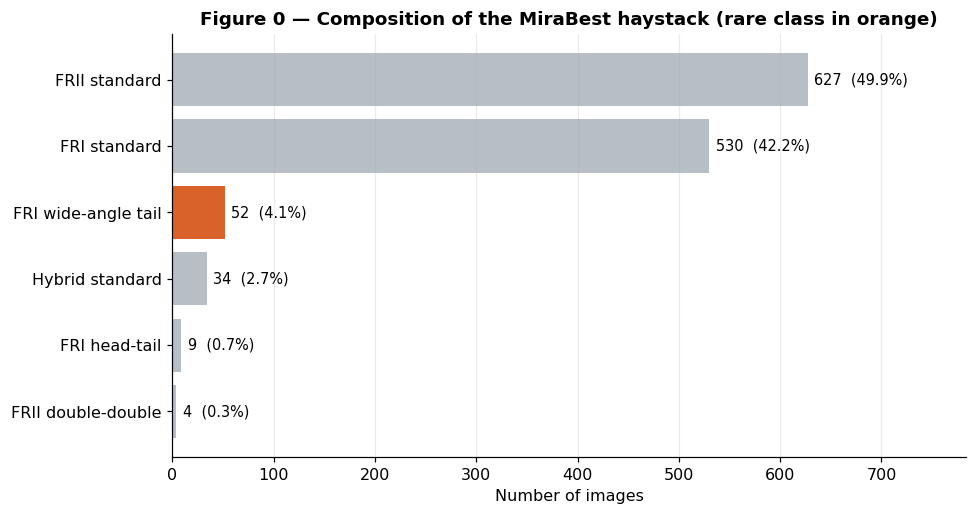

**Takeaway:** only **52 of 1256 images (4.1%)** are wide-angle-tail sources. Phase 1's bent-tailed class was **164 of 660 (24.8%)**, so this second test is a *harder* needle-in-a-haystack problem: the rare class is roughly 6× scarcer.

In [11]:
groups = group_names(all_fine_labels_arr)
counts = Counter(groups)
order = sorted(counts, key=counts.get, reverse=True)
rare_group = decode_label(WAT_LABELS[0])[0]

fig, ax = plt.subplots(figsize=(9, 0.5 * len(order) + 1.8))
ypos = np.arange(len(order))[::-1]
bar_colors = [PHASE2_COLOR if g == rare_group else "#B8BEC6" for g in order]
ax.barh(ypos, [counts[g] for g in order], color=bar_colors)
ax.set_yticks(ypos)
ax.set_yticklabels(order)
xmax = max(counts.values())
for y, g in zip(ypos, order):
    ax.text(counts[g] + xmax * 0.01, y, f"{counts[g]}  ({counts[g] / len(groups):.1%})",
            va="center", fontsize=9.5)
ax.set_xlim(0, xmax * 1.25)
ax.set_xlabel("Number of images")
ax.set_title("Figure 0 — Composition of the MiraBest haystack (rare class in orange)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
save_fig(fig, "fig0_haystack_composition")
plt.show()

n_rare_here = int(is_wat.sum())
share_here = n_rare_here / len(groups)
scarcity = (0.248 / share_here) if share_here > 0 else float("nan")
display(Markdown(
    f"**Takeaway:** only **{n_rare_here} of {len(groups)} images ({share_here:.1%})** are "
    f"wide-angle-tail sources. Phase 1's bent-tailed class was **164 of 660 (24.8%)**, so this second "
    f"test is a *harder* needle-in-a-haystack problem: the rare class is roughly "
    f"{scarcity:.0f}× scarcer."
))


## 7. From here, the pipeline is identical to Phase 1

Once `all_images` and a boolean `is_wat` rare-class mask are correctly
populated above, the remaining steps reuse the **exact same, already-
validated** code from the project repository's `src/` modules — not a
rewritten copy — so the comparison between datasets is methodologically
apples-to-apples.


In [12]:
import subprocess
import os

REPO_DIR = "radio-source-discovery"
if os.path.isdir(REPO_DIR):
    print(f"{REPO_DIR} already exists (from an earlier run in this session) — "
          f"pulling latest instead of re-cloning.")
    subprocess.run(["git", "-C", REPO_DIR, "pull"], check=False)
else:
    subprocess.run(["git", "clone", "--depth", "1",
                    "https://github.com/tallhaishtiaque/radio-source-discovery.git"],
                   check=True)

import sys
if REPO_DIR not in sys.path:
    sys.path.insert(0, REPO_DIR)

from src.eval.needle_in_haystack import evaluate_needle_in_haystack, random_baseline
print("Imported the project's own validated evaluation code.")


Cloning into 'radio-source-discovery'...


Imported the project's own validated evaluation code.


In [13]:
dinov2 = torch.hub.load("facebookresearch/dinov2", "dinov2_vits14")
dinov2.eval().to(DEVICE)

preprocess = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.Grayscale(num_output_channels=3),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])

@torch.no_grad()
def extract_embeddings_from_arrays(image_arrays, batch_size=32):
    all_feats = []
    for i in tqdm(range(0, len(image_arrays), batch_size), desc="Extracting embeddings"):
        batch = image_arrays[i:i + batch_size]
        imgs = torch.stack([
            preprocess(Image.fromarray(arr).convert("L")) for arr in batch
        ])
        feats = dinov2(imgs.to(DEVICE))
        all_feats.append(feats.cpu().numpy())
    return np.concatenate(all_feats, axis=0)

embeddings = extract_embeddings_from_arrays(all_images)
print("Embeddings shape:", embeddings.shape)

labels_for_eval = np.where(is_wat, "wide_angle_tail", "other")

# Defensive check: len(labels_for_eval) can only be 0 if all_fine_labels was
# empty or mismatched relative to all_images at the point this ran. In
# practice this happens when cells are re-run out of order in Kaggle's
# persistent kernel, e.g. Sections 4/5 held stale variables from an earlier,
# different run while this cell picked up a fresh all_images. Catching it
# here gives a clear, actionable message instead of a cryptic
# ZeroDivisionError several lines later inside random_baseline().
assert len(all_images) == len(all_fine_labels) == len(labels_for_eval) > 0, (
    f"Inconsistent state detected: all_images={len(all_images)}, "
    f"all_fine_labels={len(all_fine_labels)}, labels_for_eval={len(labels_for_eval)}. "
    f"These should all match and be non-zero. This almost always means cells "
    f"were re-run out of order and some variables are stale from an earlier "
    f"run. Fix: use the Run menu -> 'Restart & Run All' for a clean, "
    f"consistent state, then try again."
)
print(f"Consistency check passed: {len(all_images)} images, "
      f"{is_wat.sum()} wide-angle-tail, {len(all_images) - is_wat.sum()} other.")
assert is_wat.sum() >= 5, (
    f"Only {is_wat.sum()} wide-angle-tail examples were found - too few to evaluate. "
    f"See Section 6's printed unique label values and adjust WAT_LABELS to match."
)

embeddings_normed = embeddings.astype("float32").copy()
faiss.normalize_L2(embeddings_normed)
index = faiss.IndexFlatIP(embeddings_normed.shape[1])
index.add(embeddings_normed)

results = evaluate_needle_in_haystack(
    index, embeddings_normed, labels_for_eval, rare_label="wide_angle_tail", k=20
)
baseline = random_baseline(labels_for_eval, "wide_angle_tail")

print(f"\nMiraBest wide-angle-tail results:")
print(f"Precision@{results['k']}: {results['precision_at_k_mean']:.3f} (std: {results['precision_at_k_std']:.3f})")
print(f"Hit-rate@{results['k']}: {results['hit_rate_at_k']:.3f}")
print(f"Random baseline: {baseline:.3f}")
print(f"Improvement over baseline: {results['precision_at_k_mean'] / baseline:.2f}x")


Downloading: "https://github.com/facebookresearch/dinov2/zipball/main" to /root/.cache/torch/hub/main.zip


/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/swiglu_ffn.py:51: UserWarning: xFormers is not available (SwiGLU)
  warnings.warn("xFormers is not available (SwiGLU)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/attention.py:33: UserWarning: xFormers is not available (Attention)
  warnings.warn("xFormers is not available (Attention)")
/root/.cache/torch/hub/facebookresearch_dinov2_main/dinov2/layers/block.py:40: UserWarning: xFormers is not available (Block)
  warnings.warn("xFormers is not available (Block)")


Downloading: "https://dl.fbaipublicfiles.com/dinov2/dinov2_vits14/dinov2_vits14_pretrain.pth" to /root/.cache/torch/hub/checkpoints/dinov2_vits14_pretrain.pth


100%|██████████| 84.2M/84.2M [00:00<00:00, 500MB/s]


Extracting embeddings:   0%|          | 0/40 [00:00<?, ?it/s]

Embeddings shape: (1256, 384)
Consistency check passed: 1256 images, 52 wide-angle-tail, 1204 other.

MiraBest wide-angle-tail results:
Precision@20: 0.074 (std: 0.061)
Hit-rate@20: 0.769
Random baseline: 0.041
Improvement over baseline: 1.79x


## 8. Results — MiraBest (Phase 2) vs Aniyan & Thorat (Phase 1)

This section turns the numbers into pictures. Everything below is computed
from **your run's actual data** — nothing is typed in by hand. Colour code
used in every figure: **blue = Phase 1 (Aniyan & Thorat, bent-tailed)**,
**orange = Phase 2 (MiraBest, wide-angle-tail)**, **grey = random guessing**.

### 8.1 Bring Phase 1 into this notebook for a like-for-like comparison

For a fair comparison, both datasets should go through *exactly the same*
code in *exactly the same session*. The next cell therefore re-runs the
Phase 1 experiment here, **if** the Phase 1 dataset is attached to this
notebook (same steps as before: *Add Input → "Radio Galaxy Images -
FRI,FRII,Bent-tailed" by manangupta15*). It also checks that the re-run
reproduces the Phase 1 headline number (precision@20 = 0.523).

If the dataset is **not** attached, the notebook still works: it falls back
to the summary numbers logged in the Phase 1 notebook, and figures that need
per-query data (curves, distributions, maps, confidence intervals for
Phase 1) simply show MiraBest only.


In [14]:
import os

PHASE1_LOGGED = dict(n_queries=164, precision_mean=0.523, precision_std=0.235,
                     hit_rate=0.988, baseline=0.248)

def _norm(s):
    return "".join(ch for ch in s.lower() if ch.isalnum())

def find_phase1_class_folders(kaggle_input=Path("/kaggle/input")):
    # Same robust detection as the Phase 1 notebook (skips the augmented copy).
    if not kaggle_input.exists():
        return None
    roots = []
    for root, dirs, files in os.walk(kaggle_input):
        rp = Path(root)
        if "augmented" in rp.name.lower():
            dirs[:] = []
            continue
        if "radio-galaxy" in rp.name.lower():
            roots.append(rp)
    if not roots:
        return None
    variants = {"FRI": {"fri", "fr1"}, "FRII": {"frii", "fr2"},
                "bent_tailed": {"bent", "benttailed", "benttail"}}
    found = {}
    for root, dirs, files in os.walk(roots[0]):
        rp = Path(root)
        if "augmented" in str(rp).lower():
            dirs[:] = []
            continue
        for label, vs in variants.items():
            if label not in found and _norm(rp.name) in vs:
                found[label] = rp
    return found if len(found) == 3 else None

def collect_pngs(folder):
    out = []
    for root, dirs, files in os.walk(folder):
        if "augmented" in root.lower():
            dirs[:] = []
            continue
        out.extend(Path(root) / f for f in files if f.lower().endswith(".png"))
    return sorted(out)

KS = [1, 2, 5, 10, 20, 30, 50]
phase1 = None

folders = find_phase1_class_folders()
if folders is None:
    print("Phase 1 dataset is NOT attached -> using the logged Phase 1 summary numbers only.")
    print("For full side-by-side curves and distributions: Add Input -> "
          "'Radio Galaxy Images - FRI,FRII,Bent-tailed' (manangupta15), then re-run this cell.")
else:
    p1_paths, p1_labels = [], []
    for label, folder in folders.items():
        files_ = collect_pngs(folder)[:300]          # same cap as Phase 1
        p1_paths += files_
        p1_labels += [label] * len(files_)
    p1_labels = np.array(p1_labels)
    p1_images = [np.array(Image.open(p).convert("L")) for p in p1_paths]
    print(f"Phase 1 images loaded: {len(p1_images)}  "
          f"({dict(Counter(p1_labels.tolist()))})")

    p1_emb = extract_embeddings_from_arrays(p1_images)
    p1_norm = p1_emb.astype("float32").copy()
    faiss.normalize_L2(p1_norm)
    p1_index = faiss.IndexFlatIP(p1_norm.shape[1])
    p1_index.add(p1_norm)

    p1_res = evaluate_needle_in_haystack(p1_index, p1_norm, p1_labels, rare_label="bent_tailed", k=20)
    p1_base = random_baseline(p1_labels, "bent_tailed")
    phase1 = dict(index=p1_index, emb=p1_norm, labels=p1_labels, rare="bent_tailed",
                  res=p1_res, baseline=p1_base)

    delta = abs(p1_res["precision_at_k_mean"] - PHASE1_LOGGED["precision_mean"])
    verdict = "reproduces the logged Phase 1 result" if delta < 0.01 else \
              f"DIFFERS from the logged Phase 1 value ({PHASE1_LOGGED['precision_mean']}) by {delta:.3f}"
    print(f"\nPhase 1 re-run: precision@20 = {p1_res['precision_at_k_mean']:.3f} "
          f"(std {p1_res['precision_at_k_std']:.3f}), baseline {p1_base:.3f} -> {verdict}")


Phase 1 dataset is NOT attached -> using the logged Phase 1 summary numbers only.
For full side-by-side curves and distributions: Add Input -> 'Radio Galaxy Images - FRI,FRII,Bent-tailed' (manangupta15), then re-run this cell.


### 8.2 Assemble both experiments into one comparable structure

The cell below computes, for each dataset, the per-query precision at
several values of *k*, the 95% bootstrap confidence intervals, and
cross-checks its numbers against the shared evaluation code from the
project repository (two independent implementations should agree exactly).


In [15]:
def build_run(name, short, color, index_, emb_norm, labels_, rare_label, shared_res, baseline_):
    pq = precision_at_k_per_query(index_, emb_norm, labels_, rare_label, KS)
    # Cross-check against the shared evaluation function at k=20.
    assert abs(pq[20].mean() - shared_res["precision_at_k_mean"]) < 1e-9, \
        "Independent precision@20 disagrees with the shared evaluation code!"
    p20 = pq[20]
    return dict(name=name, short=short, color=color, pq=pq, n_rare=len(p20),
                n_total=len(labels_), baseline=baseline_,
                p20=float(p20.mean()), p20_std=float(p20.std()),
                p20_ci=bootstrap_ci(p20), hit=float((p20 > 0).mean()),
                emb=emb_norm, labels=labels_, rare=rare_label, res=shared_res)

runs = [build_run("MiraBest (wide-angle-tail)", "MiraBest\nwide-angle-tail", PHASE2_COLOR,
                  index, embeddings_normed, labels_for_eval, "wide_angle_tail", results, baseline)]

if phase1 is not None:
    runs.insert(0, build_run("Aniyan & Thorat (bent-tailed)", "Aniyan & Thorat\nbent-tailed", PHASE1_COLOR,
                             phase1["index"], phase1["emb"], phase1["labels"], "bent_tailed",
                             phase1["res"], phase1["baseline"]))
else:
    runs.insert(0, dict(name="Aniyan & Thorat (bent-tailed)", short="Aniyan & Thorat\nbent-tailed",
                        color=PHASE1_COLOR, pq=None, n_rare=PHASE1_LOGGED["n_queries"], n_total=660,
                        baseline=PHASE1_LOGGED["baseline"], p20=PHASE1_LOGGED["precision_mean"],
                        p20_std=PHASE1_LOGGED["precision_std"], p20_ci=None,
                        hit=PHASE1_LOGGED["hit_rate"], emb=None, labels=None, rare="bent_tailed", res=None))

for r in runs:
    ci = f"  95% CI [{r['p20_ci'][0]:.3f}, {r['p20_ci'][1]:.3f}]" if r["p20_ci"] else "  (logged value, no per-query data)"
    print(f"{r['name']:32s} n_rare={r['n_rare']:4d}  P@20={r['p20']:.3f}{ci}  "
          f"baseline={r['baseline']:.3f}  lift={r['p20'] / r['baseline']:.2f}x")


Aniyan & Thorat (bent-tailed)    n_rare= 164  P@20=0.523  (logged value, no per-query data)  baseline=0.248  lift=2.11x
MiraBest (wide-angle-tail)       n_rare=  52  P@20=0.074  95% CI [0.059, 0.090]  baseline=0.041  lift=1.79x


### 8.3 Figure 1 — The headline comparison

Four panels, one message each. **(a) Precision@20:** of the 20 galaxies
the search returns, what fraction are truly the rare type — next to what
random guessing would give (grey). **(b) Lift:** how many times better than
random. **(c) Normalised gain:** the *fair* way to compare the two
datasets — it measures **what fraction of the possible improvement over
random the search achieved** (0 = no better than guessing, 1 = perfect).
This matters because the rare class is a very different share of each
dataset (about 25% in Phase 1, only a few % in MiraBest): a rarer class has
far more room for a big "× lift" even from a mediocre search, so lift alone
would flatter MiraBest. **(d) Hit-rate:** how often the top-20 contains *at
least one* correct match. Thin black bars are **95% confidence intervals**;
if two intervals overlap heavily, the datasets are not clearly different.


saved -> figures/fig1_headline_comparison.png


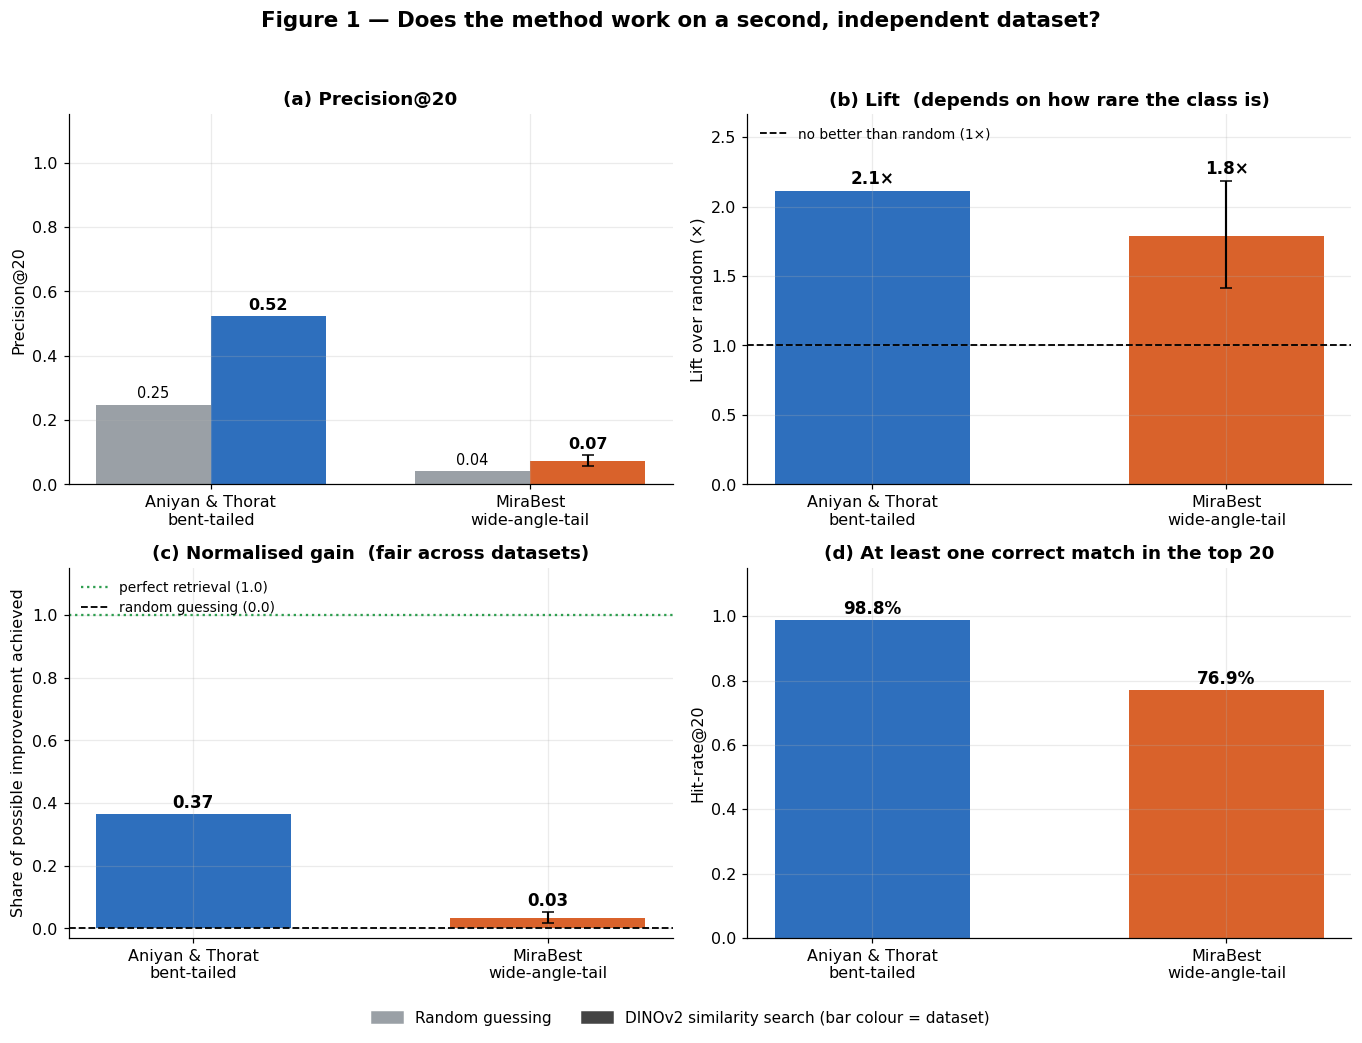

In [16]:
from matplotlib.patches import Patch

def norm_gain(p, b):
    # Prevalence-adjusted score: 0 = random guessing, 1 = perfect retrieval.
    return (p - b) / (1 - b)

for r in runs:
    r["ng"] = norm_gain(r["p20"], r["baseline"])
    r["ng_ci"] = (tuple(norm_gain(v, r["baseline"]) for v in r["p20_ci"]) if r["p20_ci"] else None)

fig, axes = plt.subplots(2, 2, figsize=(12.5, 9.4))
axA, axB, axC, axD = axes.ravel()
x = np.arange(len(runs))
w = 0.36
labels_x = [r["short"] for r in runs]

# (a) precision@20 vs random baseline -----------------------------------------
axA.bar(x - w / 2, [r["baseline"] for r in runs], w, color=BASE_COLOR)
axA.bar(x + w / 2, [r["p20"] for r in runs], w, color=[r["color"] for r in runs])
for xi, r in zip(x, runs):
    axA.text(xi - w / 2, r["baseline"] + 0.02, f"{r['baseline']:.2f}", ha="center", fontsize=9.5)
    top = r["p20"]
    if r["p20_ci"]:
        axA.errorbar(xi + w / 2, r["p20"], yerr=[[r["p20"] - r["p20_ci"][0]], [r["p20_ci"][1] - r["p20"]]],
                     color="black", capsize=4, lw=1.4)
        top = r["p20_ci"][1]
    axA.text(xi + w / 2, top + 0.02, f"{r['p20']:.2f}", ha="center", fontsize=10.5, fontweight="bold")
axA.set_ylim(0, 1.15); axA.set_yticks(np.arange(0, 1.01, 0.2))
axA.set_xticks(x); axA.set_xticklabels(labels_x)
axA.set_ylabel("Precision@20"); axA.set_title("(a) Precision@20")

# (b) lift ----------------------------------------------------------------------
lifts = [r["p20"] / r["baseline"] for r in runs]
tops = [(r["p20_ci"][1] / r["baseline"]) if r["p20_ci"] else l for r, l in zip(runs, lifts)]
ymax_b = max(tops) * 1.22
for xi, r, lift in zip(x, runs, lifts):
    axB.bar(xi, lift, 0.55, color=r["color"])
    top = lift
    if r["p20_ci"]:
        lo, hi = r["p20_ci"][0] / r["baseline"], r["p20_ci"][1] / r["baseline"]
        axB.errorbar(xi, lift, yerr=[[lift - lo], [hi - lift]], color="black", capsize=4, lw=1.4)
        top = hi
    axB.text(xi, top + 0.02 * ymax_b, f"{lift:.1f}×", ha="center", fontsize=11, fontweight="bold")
axB.axhline(1.0, color="black", ls="--", lw=1.2, label="no better than random (1×)")
axB.set_ylim(0, ymax_b)
axB.set_xticks(x); axB.set_xticklabels(labels_x)
axB.set_ylabel("Lift over random (×)")
axB.set_title("(b) Lift  (depends on how rare the class is)")
axB.legend(loc="upper left", fontsize=9)

# (c) normalised gain -------------------------------------------------------------
for xi, r in zip(x, runs):
    axC.bar(xi, r["ng"], 0.55, color=r["color"])
    top = r["ng"]
    if r["ng_ci"]:
        axC.errorbar(xi, r["ng"], yerr=[[r["ng"] - r["ng_ci"][0]], [r["ng_ci"][1] - r["ng"]]],
                     color="black", capsize=4, lw=1.4)
        top = r["ng_ci"][1]
    axC.text(xi, top + 0.02, f"{r['ng']:.2f}", ha="center", fontsize=11, fontweight="bold")
axC.axhline(1.0, color="#2E9E4F", ls=":", lw=1.5, label="perfect retrieval (1.0)")
axC.axhline(0.0, color="black", ls="--", lw=1.2, label="random guessing (0.0)")
axC.set_ylim(-0.03, 1.15); axC.set_yticks(np.arange(0, 1.01, 0.2))
axC.set_xticks(x); axC.set_xticklabels(labels_x)
axC.set_ylabel("Share of possible improvement achieved")
axC.set_title("(c) Normalised gain  (fair across datasets)")
axC.legend(loc="upper left", fontsize=9)

# (d) hit-rate ------------------------------------------------------------------------
for xi, r in zip(x, runs):
    axD.bar(xi, r["hit"], 0.55, color=r["color"])
    axD.text(xi, r["hit"] + 0.02, f"{r['hit']:.1%}", ha="center", fontsize=11, fontweight="bold")
axD.set_ylim(0, 1.15); axD.set_yticks(np.arange(0, 1.01, 0.2))
axD.set_xticks(x); axD.set_xticklabels(labels_x)
axD.set_ylabel("Hit-rate@20")
axD.set_title("(d) At least one correct match in the top 20")

fig.legend(handles=[Patch(color=BASE_COLOR, label="Random guessing"),
                    Patch(color="#444444", label="DINOv2 similarity search (bar colour = dataset)")],
           loc="lower center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 0.0), fontsize=10)
fig.suptitle("Figure 1 — Does the method work on a second, independent dataset?",
             fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0.04, 1, 0.97])
save_fig(fig, "fig1_headline_comparison")
plt.show()


### 8.4 Figure 2 — How does performance change as we look at more results?

Left: precision@k for k = 1 to 50 — *how pure is the shortlist as it gets
longer?* (Solid line = search, dashed line = random guessing for the same
dataset.) Right: the same data as **normalised gain** — the share of the
possible improvement over random that the search achieves at each list
length (0 = random, 1 = perfect), which is directly comparable between the
two datasets. Shaded bands are 95% confidence intervals. *How to read it:* a
curve that stays far above its dashed line means the method is useful at
every list length; a curve that falls towards the dashed line means the
extra results are mostly noise.


saved -> figures/fig2_precision_at_k_curves.png


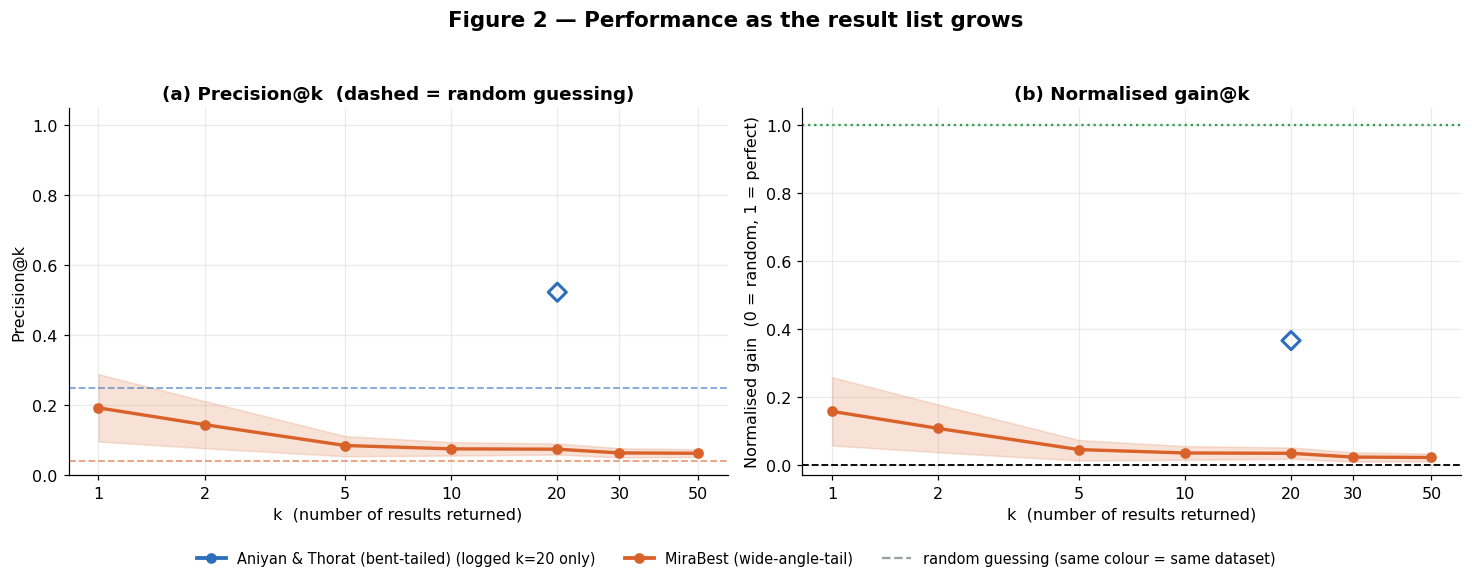

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

for r in runs:
    b0 = r["baseline"]
    if r["pq"] is None:
        # Only the logged k=20 point is available.
        axes[0].scatter([20], [r["p20"]], marker="D", s=70, facecolors="none",
                        edgecolors=r["color"], linewidths=2, zorder=5)
        axes[1].scatter([20], [norm_gain(r["p20"], b0)], marker="D", s=70, facecolors="none",
                        edgecolors=r["color"], linewidths=2, zorder=5)
        axes[0].axhline(b0, color=r["color"], ls="--", lw=1.2, alpha=0.6)
        continue
    means = np.array([r["pq"][k].mean() for k in KS])
    cis = np.array([bootstrap_ci(r["pq"][k], n_boot=1000) for k in KS])
    axes[0].plot(KS, means, "-o", color=r["color"], lw=2.2)
    axes[0].fill_between(KS, cis[:, 0], cis[:, 1], color=r["color"], alpha=0.18)
    axes[0].axhline(b0, color=r["color"], ls="--", lw=1.2, alpha=0.6)
    axes[1].plot(KS, norm_gain(means, b0), "-o", color=r["color"], lw=2.2)
    axes[1].fill_between(KS, norm_gain(cis[:, 0], b0), norm_gain(cis[:, 1], b0), color=r["color"], alpha=0.18)

for a_ in axes:
    a_.set_xscale("log")
    a_.set_xticks(KS); a_.set_xticklabels([str(k) for k in KS])
    a_.minorticks_off()
    a_.set_xlabel("k  (number of results returned)")
axes[0].set_ylabel("Precision@k"); axes[0].set_ylim(0, 1.05)
axes[0].set_title("(a) Precision@k  (dashed = random guessing)")
axes[1].axhline(0.0, color="black", ls="--", lw=1.2)
axes[1].axhline(1.0, color="#2E9E4F", ls=":", lw=1.5)
axes[1].set_ylabel("Normalised gain  (0 = random, 1 = perfect)"); axes[1].set_ylim(-0.03, 1.05)
axes[1].set_title("(b) Normalised gain@k")

handles = [plt.Line2D([0], [0], color=r["color"], lw=2.5, marker="o",
                      label=r["name"] + (" (logged k=20 only)" if r["pq"] is None else "")) for r in runs]
handles += [plt.Line2D([0], [0], color=BASE_COLOR, ls="--", lw=1.5, label="random guessing (same colour = same dataset)")]
fig.legend(handles=handles, loc="lower center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.0), fontsize=9.5)
fig.suptitle("Figure 2 — Performance as the result list grows", fontsize=14, fontweight="bold", y=0.995)
plt.tight_layout(rect=[0, 0.07, 1, 0.96])
save_fig(fig, "fig2_precision_at_k_curves")
plt.show()


### 8.5 Figure 3 — Is the method consistent, or does it get lucky?

An average can hide a lot. Each bar below counts how many **individual
queries** (one rare galaxy used as the search example) scored a given
precision@20. The black line is the average; the grey dashed line is what
random guessing would score. *How to read it:* bars piled up to the
**right** of the grey line mean most queries work well; a tall bar at **0**
means a group of galaxies for which the search completely fails — worth
looking at, and reported honestly.


saved -> figures/fig3_per_query_distributions.png


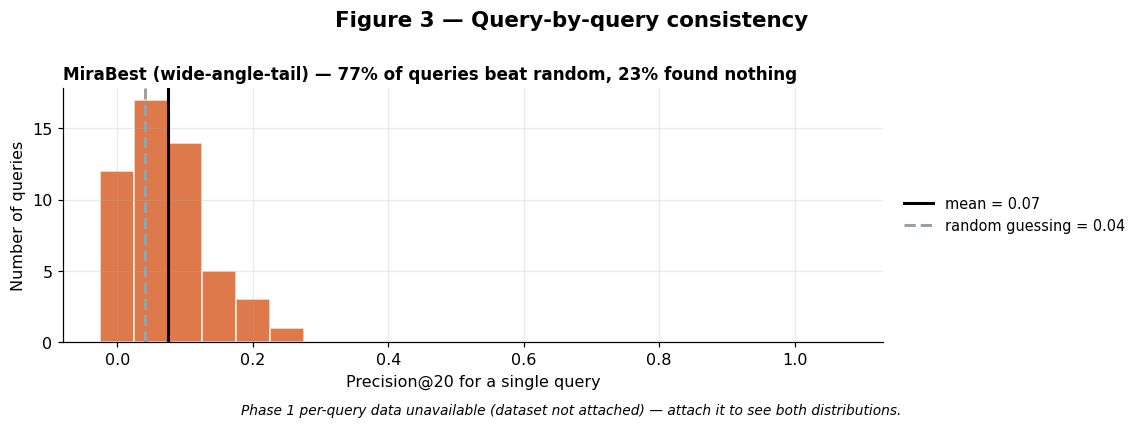

In [18]:
runs_with_pq = [r for r in runs if r["pq"] is not None]
fig, axes = plt.subplots(len(runs_with_pq), 1, figsize=(10.5, 3.6 * len(runs_with_pq)), sharex=True)
axes = np.atleast_1d(axes)
bins = np.arange(-0.025, 1.076, 0.05)   # bars centred on multiples of 0.05

for ax, r in zip(axes, runs_with_pq):
    vals = r["pq"][20]
    ax.hist(vals, bins=bins, color=r["color"], alpha=0.85, edgecolor="white")
    ax.axvline(vals.mean(), color="black", lw=2, label=f"mean = {vals.mean():.2f}")
    ax.axvline(r["baseline"], color=BASE_COLOR, ls="--", lw=2, label=f"random guessing = {r['baseline']:.2f}")
    frac_above = float((vals > r["baseline"]).mean())
    frac_zero = float((vals == 0).mean())
    ax.set_ylabel("Number of queries")
    ax.set_title(f"{r['name']} — {frac_above:.0%} of queries beat random, "
                 f"{frac_zero:.0%} found nothing", loc="left", fontsize=11)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), fontsize=9.5)
axes[-1].set_xlabel("Precision@20 for a single query")
if len(runs_with_pq) < len(runs):
    fig.text(0.5, -0.02, "Phase 1 per-query data unavailable (dataset not attached) — attach it to see both distributions.",
             ha="center", fontsize=9, style="italic")
fig.suptitle("Figure 3 — Query-by-query consistency", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "fig3_per_query_distributions")
plt.show()


### 8.6 Figure 4 — Can you *see* the rare class in the embedding space?

Every dot is one galaxy image; DINOv2's 384-number "fingerprint" of each
image has been squashed onto a 2-D map so it can be drawn. **Red/coloured
dots are the rare class**, grey dots are everything else. Left column:
PCA (a straight, linear squash). Right column: t-SNE (a non-linear squash
that preserves local neighbourhoods and tends to reveal clusters). *How to
read it:* if the coloured dots gather into a clump, similar-looking rare
galaxies really do sit next to each other in fingerprint space — which is
exactly what the similarity search relies on. If they are sprinkled evenly
among the grey dots, the fingerprint does not single them out.


saved -> figures/fig4_embedding_maps.png


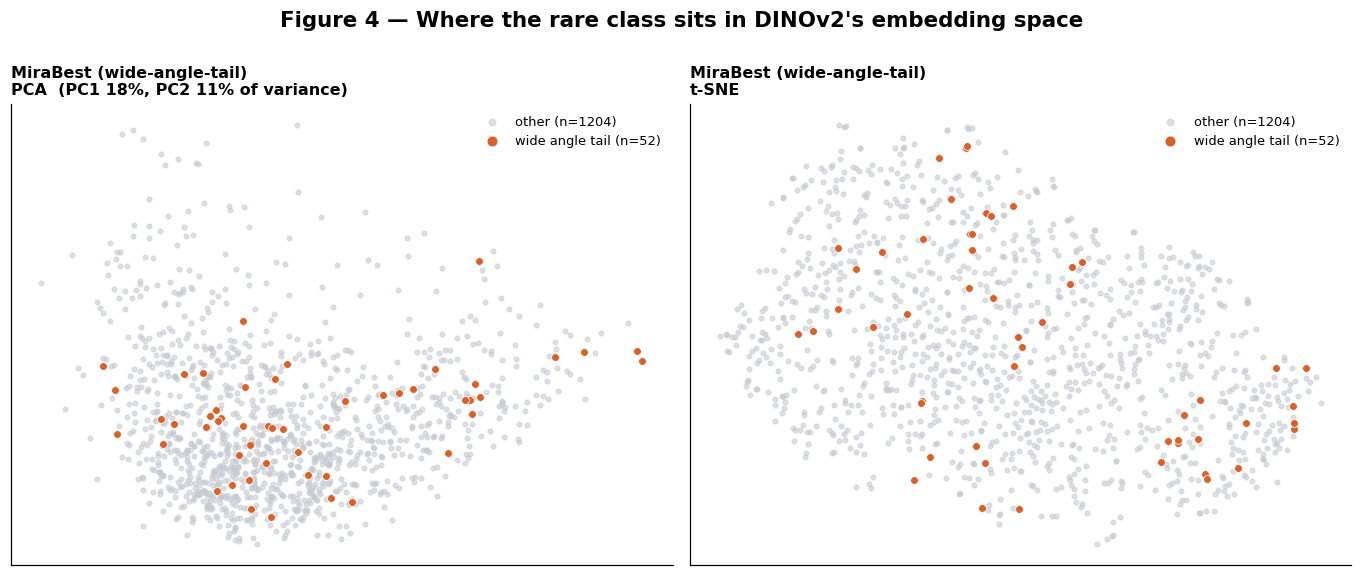

In [19]:
from sklearn.manifold import TSNE

runs_with_emb = [r for r in runs if r["emb"] is not None]
fig, axes = plt.subplots(len(runs_with_emb), 2, figsize=(12.5, 5.2 * len(runs_with_emb)))
axes = np.atleast_2d(axes)

for row, r in enumerate(runs_with_emb):
    is_rare = (r["labels"] == r["rare"])
    pca2 = PCA(n_components=2, random_state=SEED)
    xy_pca = pca2.fit_transform(r["emb"])
    xy_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
                   random_state=SEED).fit_transform(r["emb"])
    for col, (xy, title) in enumerate([
        (xy_pca, f"PCA  (PC1 {pca2.explained_variance_ratio_[0]:.0%}, PC2 {pca2.explained_variance_ratio_[1]:.0%} of variance)"),
        (xy_tsne, "t-SNE"),
    ]):
        ax = axes[row, col]
        ax.scatter(xy[~is_rare, 0], xy[~is_rare, 1], s=9, c="#C5CAD1", alpha=0.55, label=f"other (n={(~is_rare).sum()})")
        ax.scatter(xy[is_rare, 0], xy[is_rare, 1], s=26, c=r["color"], edgecolors="white",
                   linewidths=0.5, label=f"{r['rare'].replace('_', ' ')} (n={is_rare.sum()})")
        ax.set_title(f"{r['name']}\n{title}", fontsize=10.5, loc="left")
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.legend(loc="best", fontsize=8.5, markerscale=1.4)

fig.suptitle("Figure 4 — Where the rare class sits in DINOv2's embedding space", fontsize=14, fontweight="bold", y=1.0)
plt.tight_layout()
save_fig(fig, "fig4_embedding_maps")
plt.show()


### 8.7 Figure 5 — See the search actually working (and failing)

Statistics are convincing, but nothing beats looking at real examples.
Each row below is one **query** (blue frame, far left) followed by the 9
galaxies the search ranked most similar to it. **Green frame = truly
wide-angle-tail (correct); red frame = something else (a miss).** The three
rows are the **best**, a **typical** (median) and the **worst** query,
chosen automatically by their precision@20 score — failures are shown on
purpose, because a method is only trustworthy if you can see how it
fails. Captions give each neighbour's true class and its similarity score
(cosine, 1.0 = identical fingerprint).


saved -> figures/fig5_retrieval_gallery.png


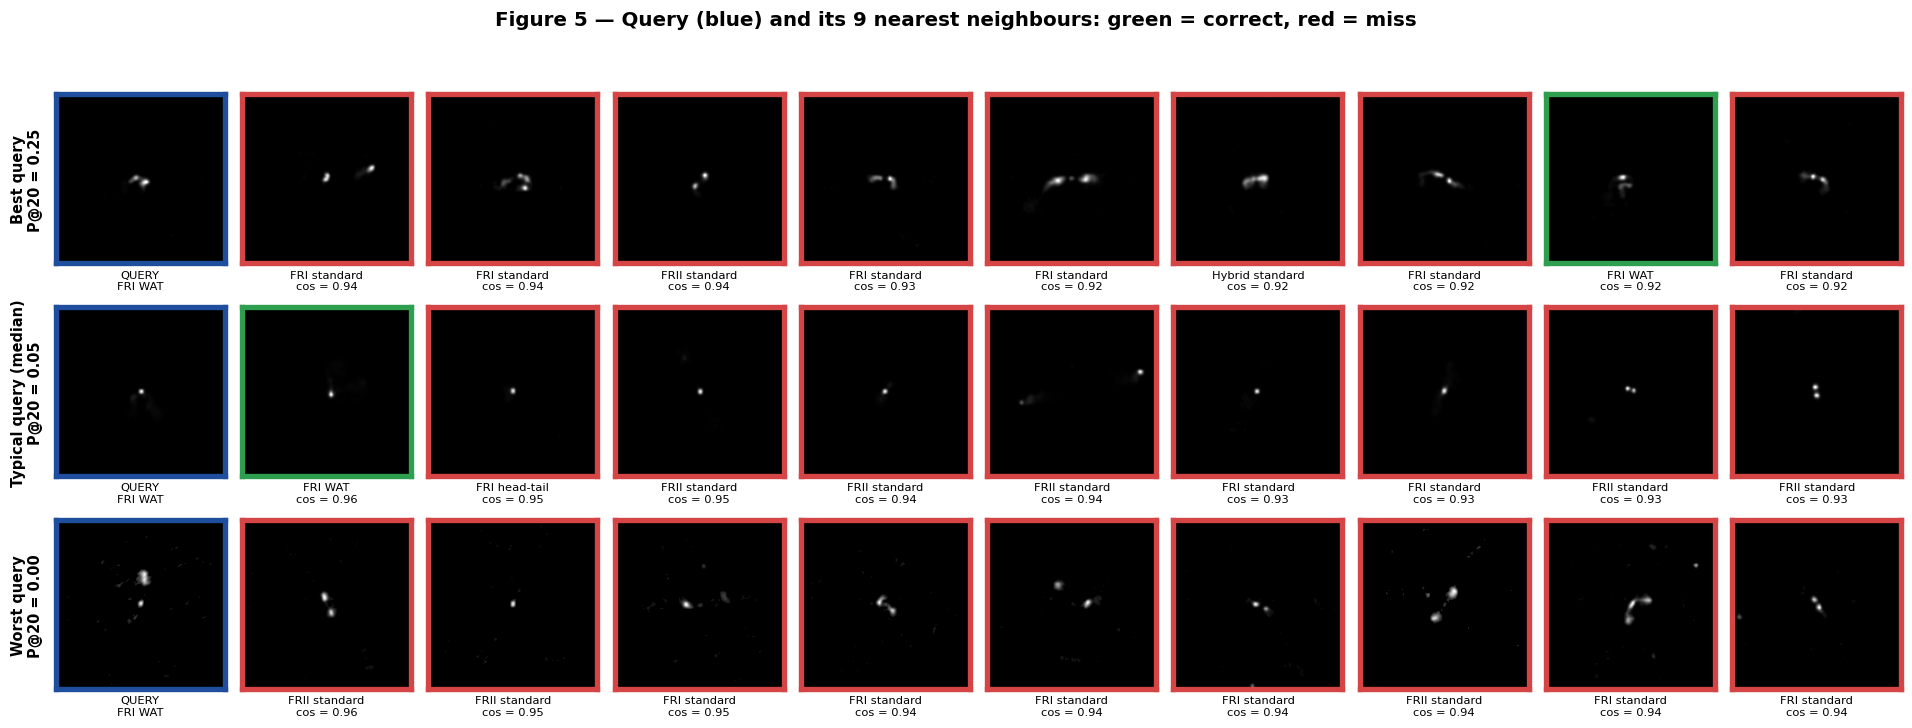

In [20]:
rare_idx = np.where(labels_for_eval == "wide_angle_tail")[0]
pq20 = results["precision_at_k_values"]
order_q = np.argsort(pq20)
picks = [("Best query", order_q[-1]),
         ("Typical query (median)", order_q[len(order_q) // 2]),
         ("Worst query", order_q[0])]

N_NEIGHBOURS = 9
fine_names = group_names(all_fine_labels_arr)
fig, axes = plt.subplots(len(picks), N_NEIGHBOURS + 1, figsize=(1.75 * (N_NEIGHBOURS + 1), 2.15 * len(picks)))

def _short(name):
    return name.replace("wide-angle tail", "WAT")

for row, (tag, qpos) in enumerate(picks):
    qi = rare_idx[qpos]
    sims, nbrs = index.search(embeddings_normed[qi:qi + 1], N_NEIGHBOURS + 1)
    keep = nbrs[0] != qi
    nbr_idx, nbr_sims = nbrs[0][keep][:N_NEIGHBOURS], sims[0][keep][:N_NEIGHBOURS]

    ax = axes[row, 0]
    ax.imshow(all_images[qi], cmap="gray")
    for s in ax.spines.values():
        s.set_visible(True); s.set_edgecolor("#1F4E9E"); s.set_linewidth(3.5)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
    ax.set_ylabel(f"{tag}\nP@20 = {pq20[qpos]:.2f}", fontsize=9.5, fontweight="bold", labelpad=8)
    ax.set_xlabel("QUERY\n" + _short(fine_names[qi]), fontsize=7.5)

    for col, (ni, sim) in enumerate(zip(nbr_idx, nbr_sims), start=1):
        ax = axes[row, col]
        ax.imshow(all_images[ni], cmap="gray")
        correct = bool(labels_for_eval[ni] == "wide_angle_tail")
        for s in ax.spines.values():
            s.set_visible(True); s.set_edgecolor("#2E9E4F" if correct else "#D64545"); s.set_linewidth(3.5)
        ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
        ax.set_xlabel(f"{_short(fine_names[ni])}\ncos = {sim:.2f}", fontsize=7.5)

fig.suptitle("Figure 5 — Query (blue) and its 9 nearest neighbours: green = correct, red = miss",
             fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
save_fig(fig, "fig5_retrieval_gallery")
plt.show()


### 8.8 Figure 6 — What does the method confuse wide-angle-tails with?

When the search returns a wrong answer, *what kind* of galaxy is it?
This is scientifically informative: if the mistakes are physically
related sources (for example other bent-jet types) the fingerprint is
capturing real morphology; if they are unrelated types, it is not.
For every wide-angle-tail query we collect its 20 neighbours and show, for
each galaxy type, **the share of all retrieved neighbours** (coloured bar)
next to **its share of the whole dataset** (grey bar). A coloured bar much
longer than its grey partner means the search is *over-selecting* that type
relative to chance; much shorter means it is *avoiding* it.


saved -> figures/fig6_neighbour_composition.png


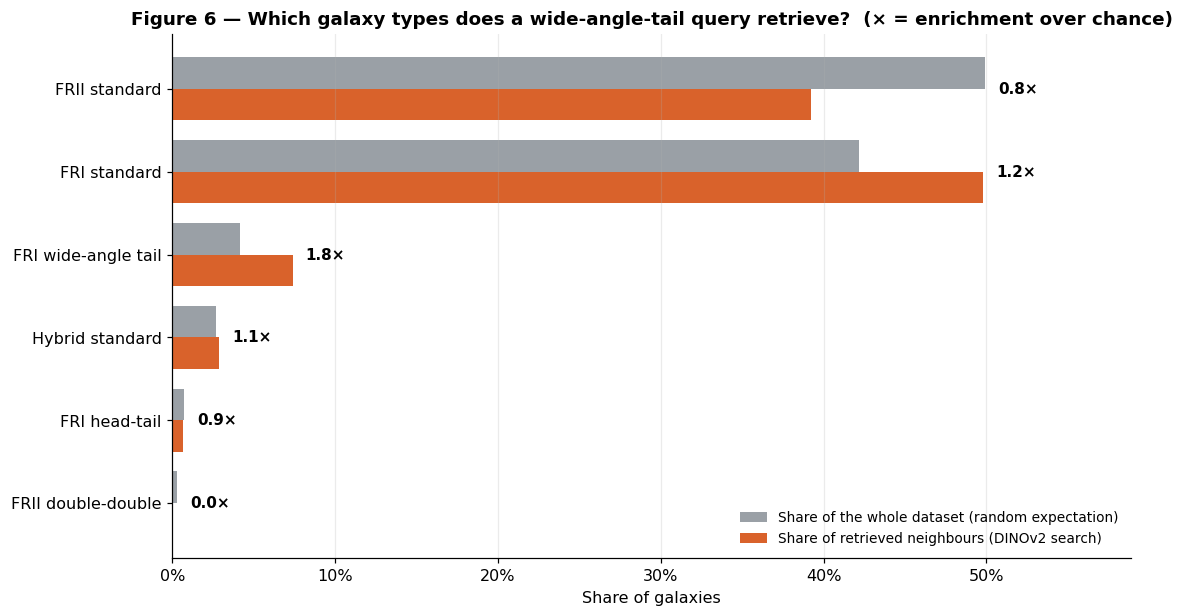

**Takeaway:** the most over-represented type in the results is **FRI wide-angle tail** (1.8× more often than chance).

In [21]:
from matplotlib.ticker import PercentFormatter

nbr_groups = []
for qi in rare_idx:
    _, nn = index.search(embeddings_normed[qi:qi + 1], 21)
    nn = nn[0][nn[0] != qi][:20]
    nbr_groups.extend(fine_names[nn].tolist())

nbr_counts = Counter(nbr_groups)
data_counts = Counter(fine_names.tolist())
cats = sorted(data_counts, key=data_counts.get, reverse=True)
share_nbr = np.array([nbr_counts.get(c, 0) / len(nbr_groups) for c in cats])
share_all = np.array([data_counts[c] / len(fine_names) for c in cats])

fig, ax = plt.subplots(figsize=(10.5, 0.62 * len(cats) + 2))
ypos = np.arange(len(cats))[::-1]
h = 0.38
ax.barh(ypos + h / 2, share_all, h, color=BASE_COLOR, label="Share of the whole dataset (random expectation)")
ax.barh(ypos - h / 2, share_nbr, h, color=PHASE2_COLOR, label="Share of retrieved neighbours (DINOv2 search)")
for y, sa, sn in zip(ypos, share_all, share_nbr):
    ratio = sn / sa if sa > 0 else np.nan
    ax.text(max(sa, sn) + 0.008, y, f"{ratio:.1f}×", va="center", fontsize=10, fontweight="bold")
ax.set_yticks(ypos); ax.set_yticklabels(cats)
ax.set_xlabel("Share of galaxies"); ax.xaxis.set_major_formatter(PercentFormatter(1.0))
ax.set_xlim(0, max(share_all.max(), share_nbr.max()) * 1.18)
ax.grid(axis="y", visible=False)
ax.set_title("Figure 6 — Which galaxy types does a wide-angle-tail query retrieve?  (× = enrichment over chance)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
save_fig(fig, "fig6_neighbour_composition")
plt.show()

top_enriched = max(((c, sn / sa) for c, sa, sn in zip(cats, share_all, share_nbr) if sa > 0), key=lambda t: t[1])
display(Markdown(f"**Takeaway:** the most over-represented type in the results is **{top_enriched[0]}** "
                 f"({top_enriched[1]:.1f}× more often than chance)."))


### 8.9 Summary table and verdict (generated from this run)

The table and plain-language verdict below are produced automatically from
the numbers above, so they always match the figures. Because the two
datasets have very different rare-class shares, the statistical test at the
end compares **normalised gain** (fair across datasets), not raw lift. It
uses a bootstrap on the *difference* between the two datasets' scores.


In [22]:
def fmt_ci(ci, digits=2):
    return f"[{ci[0]:.{digits}f}, {ci[1]:.{digits}f}]" if ci else "n/a (logged only)"

rows = ["| Dataset | Rare class | Rare examples (n) | Rare share | Precision@20 (95% CI) | Random baseline | Lift | Normalised gain (95% CI) | Hit-rate@20 |",
        "|---|---|---|---|---|---|---|---|---|"]
for r in runs:
    rows.append(
        f"| {r['name'].split(' (')[0]} | {r['rare'].replace('_', ' ')} | {r['n_rare']} "
        f"| {r['n_rare'] / r['n_total']:.1%} | {r['p20']:.3f} {fmt_ci(r['p20_ci'], 3)} "
        f"| {r['baseline']:.3f} | {r['p20'] / r['baseline']:.1f}× "
        f"| {r['ng']:.2f} {fmt_ci(r['ng_ci'])} | {r['hit']:.1%} |")
display(Markdown("\n".join(rows)))

p1r, p2r = runs[0], runs[1]
lines = []

# 1) Is MiraBest better than chance at all?
if p2r["p20_ci"][0] > p2r["baseline"]:
    lines.append(f"- **MiraBest beats random guessing.** Precision@20 = {p2r['p20']:.3f}, and even the "
                 f"*lower* end of its 95% confidence interval ({p2r['p20_ci'][0]:.3f}) is above the random "
                 f"baseline ({p2r['baseline']:.3f}), so the improvement is statistically real, not luck.")
else:
    lines.append(f"- **MiraBest result is inconclusive.** The lower end of the 95% CI "
                 f"({p2r['p20_ci'][0]:.3f}) does not clear the random baseline ({p2r['baseline']:.3f}); with only "
                 f"{p2r['n_rare']} rare examples we cannot rule out chance. Report it as inconclusive, not as success.")

# 2) Why raw lift is not comparable
lines.append(f"- **Why we compare normalised gain, not lift:** the rare class is "
             f"{p1r['n_rare'] / p1r['n_total']:.1%} of Phase 1 but only {p2r['n_rare'] / p2r['n_total']:.1%} of "
             f"MiraBest, so raw lift ({p1r['p20'] / p1r['baseline']:.1f}× vs {p2r['p20'] / p2r['baseline']:.1f}×) "
             f"is not like-for-like. Normalised gain is {p1r['ng']:.2f} (Phase 1) vs {p2r['ng']:.2f} (MiraBest) "
             f"— the share of the possible improvement over random that each search achieved.")

# 3) Are the two datasets statistically different?
if p1r["pq"] is not None:
    rng = np.random.default_rng(SEED)
    v1, v2 = p1r["pq"][20], p2r["pq"][20]
    m1 = rng.choice(v1, (5000, len(v1))).mean(axis=1)
    m2 = rng.choice(v2, (5000, len(v2))).mean(axis=1)
    d = norm_gain(m2, p2r["baseline"]) - norm_gain(m1, p1r["baseline"])
    dlo, dhi = np.percentile(d, [2.5, 97.5])
    if dlo <= 0 <= dhi:
        lines.append(f"- **Phase 1 vs Phase 2:** difference in normalised gain (MiraBest − Phase 1) = "
                     f"{np.mean(d):+.2f}, 95% CI [{dlo:+.2f}, {dhi:+.2f}] **includes 0** → the two datasets "
                     f"are **not statistically distinguishable**; the method behaves consistently.")
    else:
        direction = "higher" if np.mean(d) > 0 else "lower"
        lines.append(f"- **Phase 1 vs Phase 2:** difference in normalised gain = {np.mean(d):+.2f}, 95% CI "
                     f"[{dlo:+.2f}, {dhi:+.2f}] **excludes 0** → MiraBest performance is significantly "
                     f"{direction} than Phase 1. Worth investigating why (image resolution, rare-class "
                     f"prevalence, or selection differences between the two source catalogues).")
else:
    lines.append("- **Phase 1 vs Phase 2:** attach the Phase 1 dataset and re-run Section 8.1 to get a "
                 "statistical comparison of the two datasets.")
display(Markdown("### Verdict\n" + "\n".join(lines)))


| Dataset | Rare class | Rare examples (n) | Rare share | Precision@20 (95% CI) | Random baseline | Lift | Normalised gain (95% CI) | Hit-rate@20 |
|---|---|---|---|---|---|---|---|---|
| Aniyan & Thorat | bent tailed | 164 | 24.8% | 0.523 n/a (logged only) | 0.248 | 2.1× | 0.37 n/a (logged only) | 98.8% |
| MiraBest | wide angle tail | 52 | 4.1% | 0.074 [0.059, 0.090] | 0.041 | 1.8× | 0.03 [0.02, 0.05] | 76.9% |

### Verdict
- **MiraBest beats random guessing.** Precision@20 = 0.074, and even the *lower* end of its 95% confidence interval (0.059) is above the random baseline (0.041), so the improvement is statistically real, not luck.
- **Why we compare normalised gain, not lift:** the rare class is 24.8% of Phase 1 but only 4.1% of MiraBest, so raw lift (2.1× vs 1.8×) is not like-for-like. Normalised gain is 0.37 (Phase 1) vs 0.03 (MiraBest) — the share of the possible improvement over random that each search achieved.
- **Phase 1 vs Phase 2:** attach the Phase 1 dataset and re-run Section 8.1 to get a statistical comparison of the two datasets.

### 8.10 Files produced

All figures were saved as high-resolution PNGs (200 dpi) in the `figures/`
folder, ready for a paper or conference slides. On Kaggle they appear under
the notebook's **Output** tab after you *Save Version*.


In [23]:
print("Saved figures:")
for p in sorted(FIG_DIR.glob("*.png")):
    print(f"  {p}   ({p.stat().st_size / 1024:.0f} KB)")


Saved figures:
  figures/fig0_haystack_composition.png   (86 KB)
  figures/fig1_headline_comparison.png   (235 KB)
  figures/fig2_precision_at_k_curves.png   (158 KB)
  figures/fig3_per_query_distributions.png   (95 KB)
  figures/fig4_embedding_maps.png   (293 KB)
  figures/fig5_retrieval_gallery.png   (192 KB)
  figures/fig6_neighbour_composition.png   (105 KB)


## 9. Limitations specific to this notebook

- **Small rare class.** With only a few dozen wide-angle-tail examples, single
  numbers are noisy — which is exactly why every headline number above
  carries a bootstrap 95% confidence interval and why the summary tests the
  *difference* between datasets rather than eyeballing two bars.
- **Two Zenodo records exist for MiraBest, with different label detail.**
  Record 4288837 carries only binary FRI/FRII labels (found by running the
  first version of this notebook and seeing `unique values: [0, 1]`). This
  version uses record 5588282, whose own description gives the full
  three-digit scheme; Section 4 checks this automatically by looking for a
  class with more than 2 distinct label values.
- **Label encoding is detected, not assumed.** The dataset's catalogue uses
  three-digit codes (wide-angle-tail = 102/112) but the files store reduced
  single-digit labels (wide-angle-tail = 1 confident, 4 uncertain). Section 6
  detects which one the loaded class uses and, for the reduced encoding,
  verifies all ten class counts against the published Table 2; it stops with a
  clear message rather than continuing on a wrong or missing label.
- **Different image resolution and different catalogues.** Phase 1 and
  MiraBest come from different source catalogues and pixel scales; both are
  resized to 224×224 for DINOv2. Differences in results may partly reflect
  these dataset differences rather than the method itself.
- **Frozen, general-purpose embeddings only.** DINOv2 is used as-is; no
  radio-specific model is compared yet (planned next).
- **Still not survey-scale.** MiraBest's ~1,256 images are a small, curated
  benchmark, not the millions-of-sources regime the project ultimately
  targets.

## 10. Next steps (from the project roadmap)

1. Compare against a **radio-specific self-supervised embedding** on the same
   two datasets, using this exact figure set for a like-for-like comparison.
2. Scale the same pipeline to a **LoTSS-DR2 subset**, with an approximate
   FAISS index.
3. Cross-survey generalisation (LoTSS → EMU) and a blind rediscovery test on
   known rare objects.
